# 코드 D · 대출 장부와 고객 명부 크기 재기
**핀테크 데이터 분석 : 실제로 해보는 데이터 분석편 #01**  
원본: [fintech-data/Revolution4](https://github.com/fintech-data/Revolution4) `Loading_Data.ipynb` → 이 폴더의 `original_Loading_Data.ipynb`  
해설 페이지: https://adminmrobo.github.io/fintech_data_analysis/hands_on_01.html

> 코드를 몰라도 괜찮아요. 위에서부터 ▶ 실행 버튼만 차례로 누르면 됩니다.

## 이 코드가 하는 일
미국 P2P 대출회사의 **대출 장부(88만 건 × 74열)**를 불러와 크기(`shape`)와 열 목록(`info`)을 확인하고, 은행 고객 명부와 마케팅 명부도 크기를 잽니다.

> 비유: 도서관 서고 전체를 처음 맡은 사서가 "책장 몇 개, 선반 몇 개"부터 세는 일.

⚠️ 이 폴더의 `bank_customers.csv`와 `direct_marketimg.csv`는 **내용이 똑같은 파일**이고 첫 줄에 열 이름이 없습니다. 원본 노트북은 이 파일 대신 코드 A 저장소의 파일을 읽어서 문제가 드러나지 않았어요. 아래에서 직접 확인합니다.

In [1]:
import os, io, urllib.request
import pandas as pd
pd.set_option('display.max_columns', 12); pd.set_option('display.width', 120)

# 데이터 위치: 이 폴더의 data/ 에 있으면 그걸 쓰고, 없으면(Colab 등) GitHub에서 바로 읽습니다.
RAW = 'https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/D_loan_ledger_check/data/'
def load(name, **kw):
    local = os.path.join('data', name)
    src = local if os.path.exists(local) else RAW + urllib.parse.quote(name)
    return pd.read_csv(src, low_memory=False, **kw)
print('준비 완료')

준비 완료


In [2]:
# loan.csv(441MB)는 GitHub 한 파일 한도 때문에 gzip으로 줄인 뒤 세 조각(part0~2)으로 나눠 두었습니다.
# 조각을 이어 붙이면 원래 파일과 똑같습니다.
def load_loan(folder='D_loan_ledger_check', **kw):
    parts = []
    for i in range(3):
        local = os.path.join("data", f'loan.csv.gz.part{i}')
        if os.path.exists(local):
            parts.append(open(local, 'rb').read())
        else:
            parts.append(urllib.request.urlopen('https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/D_loan_ledger_check/data/' + f'loan.csv.gz.part{i}').read())
    return pd.read_csv(io.BytesIO(b''.join(parts)), compression='gzip', low_memory=False, **kw)

In [3]:
loan = load_loan()
loan.shape

(887379, 74)

In [4]:
loan['loan_status'].value_counts()

loan_status
Current                                                601779
Fully Paid                                             207723
Charged Off                                             45248
Late (31-120 days)                                      11591
Issued                                                   8460
In Grace Period                                          6253
Late (16-30 days)                                        2357
Does not meet the credit policy. Status:Fully Paid       1988
Default                                                  1219
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

In [5]:
# 신용등급(A가 가장 좋음)별 평균 금리(%)
loan.groupby('grade')['int_rate'].mean().round(2)

grade
A     7.24
B    10.83
C    13.98
D    17.18
E    19.90
F    23.58
G    25.63
Name: int_rate, dtype: float64

In [6]:
# 90% 넘게 비어 있는 열
null_rate = loan.isna().mean()
null_rate[null_rate > 0.9].round(3).sort_values(ascending=False)

annual_inc_joint             0.999
dti_joint                    0.999
verification_status_joint    0.999
il_util                      0.979
mths_since_rcnt_il           0.977
open_il_6m                   0.976
open_il_12m                  0.976
open_il_24m                  0.976
open_acc_6m                  0.976
total_bal_il                 0.976
open_rv_12m                  0.976
open_rv_24m                  0.976
max_bal_bc                   0.976
all_util                     0.976
inq_fi                       0.976
total_cu_tl                  0.976
inq_last_12m                 0.976
dtype: float64

In [7]:
A_file = '../A_customer_data_tour/data/Bank_customers_data.csv'
bank_customers = pd.read_csv(A_file if os.path.exists(A_file) else RAW.replace('D_loan_ledger_check', 'A_customer_data_tour') + 'Bank_customers_data.csv')
print('코드 A의 은행 고객 명부:', bank_customers.shape)

코드 A의 은행 고객 명부: (10127, 21)


In [8]:
same = load('bank_customers.csv', header=None).equals(load('direct_marketimg.csv', header=None))
print('두 파일이 똑같은가?', same)
b4 = load('bank_customers.csv')
print('그냥 읽으면 열 이름이 첫 고객 값이 됩니다:', list(b4.columns[:4]), b4.shape)
b4 = load('bank_customers.csv', header=None, names=bank_customers.columns)
print('header=None으로 읽으면:', b4.shape)

두 파일이 똑같은가? True
그냥 읽으면 열 이름이 첫 고객 값이 됩니다: ['768805383', 'Existing Customer', '45', 'M'] (10126, 21)
header=None으로 읽으면: (10127, 21)


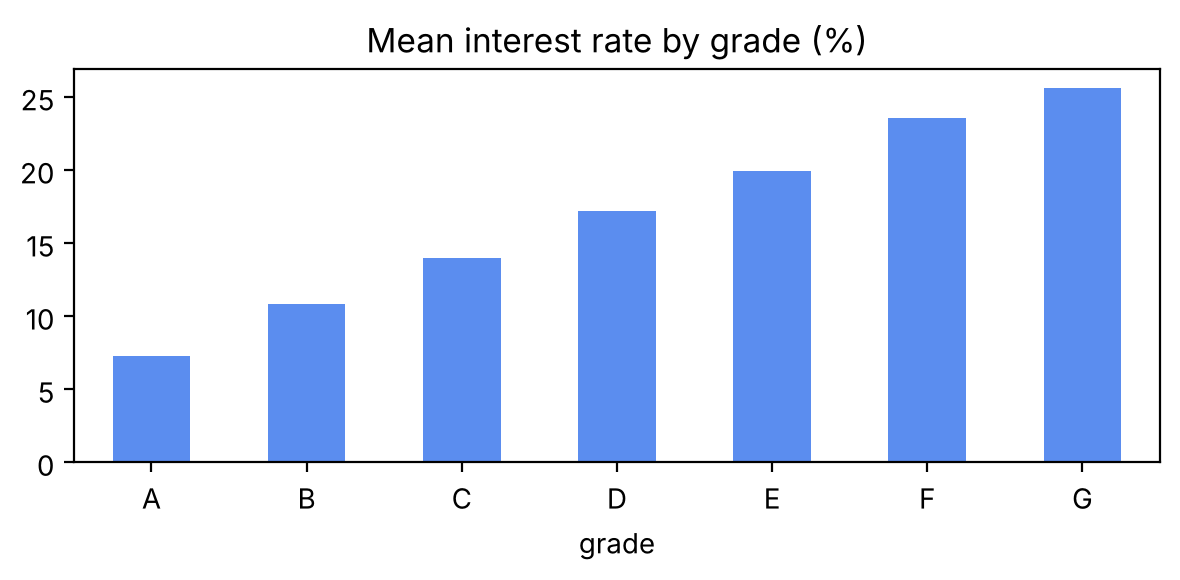

In [9]:
import matplotlib.pyplot as plt
loan.groupby('grade')['int_rate'].mean().plot.bar(rot=0, color='#5b8def', title='Mean interest rate by grade (%)', figsize=(6, 3)); plt.tight_layout(); plt.show()